# ==============================================
# 04_CausalImpact_Analysis.ipynb
# ==============================================


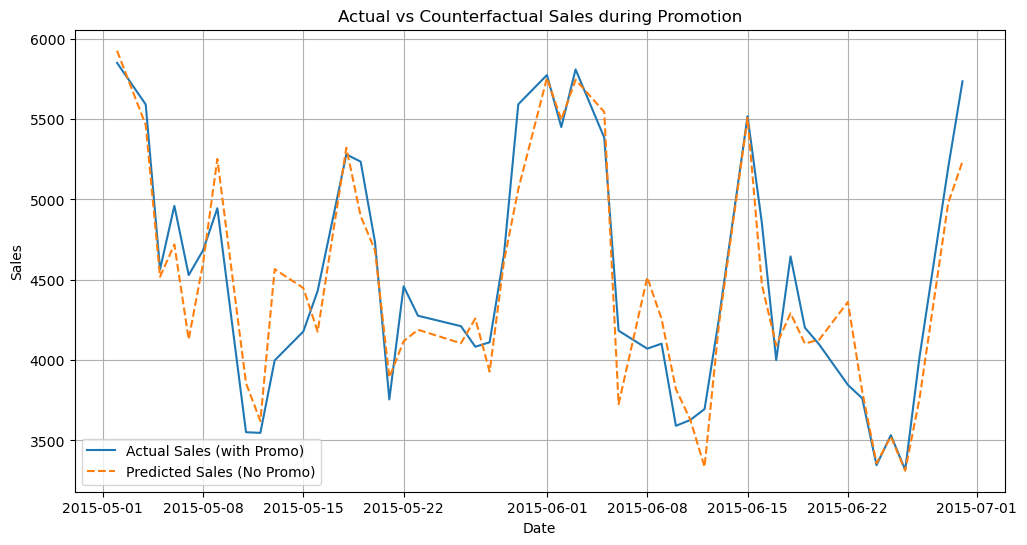


===== Causal Impact Manual Analysis =====
Average Lift in Sales: $39.96
Relative Lift: 0.90%
Counterfactual Prediction RMSE: 253.73


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Load your feature engineered dataset
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/feature_engineered_rossmann.csv', parse_dates=['Date'])
store_id = 1
df_store = df[df['Store'] == store_id].copy()

# Use only relevant columns
data = df_store[['Date', 'Sales', 'Customers']].dropna()

# Create time-based features
data['DayOfWeek'] = data['Date'].dt.dayofweek
data['Month'] = data['Date'].dt.month

# Pre-Period and Post-Period (Manual selection)
pre_period = ['2015-03-01', '2015-04-30']
post_period = ['2015-05-01', '2015-06-30']

pre_data = data[(data['Date'] >= pre_period[0]) & (data['Date'] <= pre_period[1])]
post_data = data[(data['Date'] >= post_period[0]) & (data['Date'] <= post_period[1])]

# Prepare X and y
features = ['Customers', 'DayOfWeek', 'Month']
X_pre = pre_data[features]
y_pre = pre_data['Sales']

X_post = post_data[features]
y_post = post_data['Sales']

# Fit model on pre-period (before promotion)
model = LinearRegression()
model.fit(X_pre, y_pre)

# Predict what would have happened without promo (counterfactual)
y_pred_counterfactual = model.predict(X_post)

# Calculate Actual vs Counterfactual
lift = y_post.values - y_pred_counterfactual

# Metrics
average_lift = np.mean(lift)
relative_lift = (average_lift / np.mean(y_pred_counterfactual)) * 100

# RMSE
rmse_cf = np.sqrt(mean_squared_error(y_post, y_pred_counterfactual))

# Plot
plt.figure(figsize=(12,6))
plt.plot(post_data['Date'], y_post, label='Actual Sales (with Promo)')
plt.plot(post_data['Date'], y_pred_counterfactual, label='Predicted Sales (No Promo)', linestyle='--')
plt.title('Actual vs Counterfactual Sales during Promotion')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid()
plt.show()

# Print results
print("\n===== Causal Impact Manual Analysis =====")
print(f"Average Lift in Sales: ${average_lift:.2f}")
print(f"Relative Lift: {relative_lift:.2f}%")
print(f"Counterfactual Prediction RMSE: {rmse_cf:.2f}")
